In [1]:
# Step 1: Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [3]:
# Step 2: Load the ECG dataset
# The dataset has 140 ECG signal values and one label column.
data = pd.read_csv("ecg.csv", header=None)
# Separate ECG signal values and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("ECG data shape:", X.shape)

ECG data shape: (4998, 140)


In [4]:
# Step 3: Preprocess the ECG data
# Fill missing values, if any.
X = pd.DataFrame(X).ffill().bfill().values

# Select normal ECG signals for training.
# This assumes label 0 represents normal ECG.
# Change 0 to 1 if your dataset uses label 1 for normal.
X_normal = X[y == 0]

In [5]:
# Step 4: Scale the ECG signal values
# Fit the scaler using only normal ECG signals.
scaler = MinMaxScaler()

scaler.fit(X_normal)

# Transform all ECG signals using the same scaler
X = scaler.transform(X)

# Select scaled normal signals
X_normal = X[y == 0]


In [6]:
# Step 5: Split normal data into training and validation data
# The autoencoder learns only from normal ECG signals.
X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)


In [7]:
# Use all ECG signals for testing
X_test = X

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (1663, 140)
Validation data shape: (416, 140)
Testing data shape: (4998, 140)


In [8]:
# Step 6: Define the Autoencoder architecture
# The encoder compresses the ECG signal.
# The decoder reconstructs the original ECG signal.

input_layer = Input(shape=(140,))

# Encoder: compress the input into a smaller representation
encoded = Dense(64, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)

# Decoder: reconstruct the original 140 signal values
decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(140, activation="sigmoid")(decoded)

# Create the autoencoder model
autoencoder = Model(input_layer, decoded)

# Display the model architecture
autoencoder.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Step 7: Compile the Autoencoder
# Use Adam optimizer and Mean Squared Error loss.
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [10]:
# Step 8: Train the Autoencoder on normal ECG data
# Input and target are the same because it is an autoencoder.
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, X_val),
    shuffle=True
)

Epoch 1/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0174 - val_loss: 0.0072
Epoch 2/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0068 - val_loss: 0.0059
Epoch 3/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0053 - val_loss: 0.0044
Epoch 4/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0042 - val_loss: 0.0039
Epoch 5/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038 - val_loss: 0.0035
Epoch 6/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0035 - val_loss: 0.0032
Epoch 7/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0033 - val_loss: 0.0031
Epoch 8/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031 - val_loss: 0.0029
Epoch 9/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0030 - val_loss: 0.0028
Epoch 10/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0029 - val_loss: 0.0027
Epoch 11/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027 - val_loss: 0.0025
Epoch 12/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0025 - val_lo

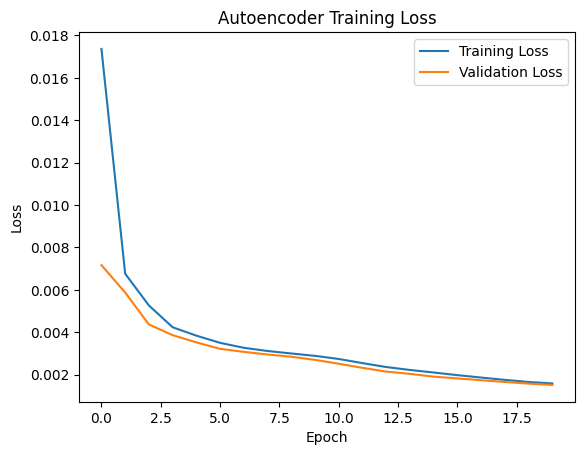

In [11]:
# Step 9: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")

plt.legend()
plt.show()

In [12]:
# Step 10: Reconstruct the testing ECG signals
reconstructed = autoencoder.predict(X_test)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [13]:
# Step 11: Calculate reconstruction error
# Higher error indicates that the ECG signal differs from
# the normal patterns learned by the autoencoder.

errors = np.mean(
    np.square(X_test - reconstructed),
    axis=1
)

In [14]:
# Step 12: Set an error threshold
# Calculate reconstruction errors for normal validation signals.
val_reconstructed = autoencoder.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=1
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [15]:
# Use the 95th percentile as the anomaly threshold
threshold = np.percentile(val_errors, 95)

print("Anomaly threshold:", threshold)

Anomaly threshold: 0.003635618951848064


In [16]:
# Step 13: Detect anomalies
# If reconstruction error exceeds the threshold,
# classify the ECG signal as anomalous.
predictions = (errors > threshold).astype(int)

print("Number of detected anomalies:", np.sum(predictions))

Number of detected anomalies: 2594


In [17]:
# Step 14: Evaluate the model using the dataset labels
# This assumes label 0 = normal and label 1 = anomaly.
# If the label meanings are reversed, change the mapping first.

print("Confusion Matrix:")
print(confusion_matrix(y, predictions))

print("Classification Report:")
print(classification_report(y, predictions))

Confusion Matrix:
[[1946  133]
 [ 458 2461]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.81      0.94      0.87      2079
         1.0       0.95      0.84      0.89      2919

    accuracy                           0.88      4998
   macro avg       0.88      0.89      0.88      4998
weighted avg       0.89      0.88      0.88      4998



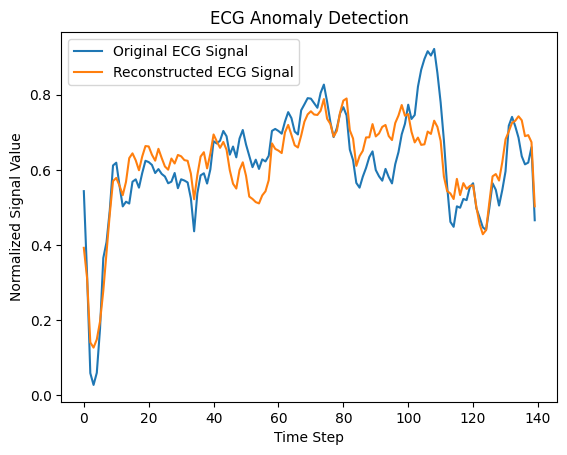

In [18]:
# Step 15: Visualize original and reconstructed ECG signals
# Display one ECG signal.

i = 0

plt.plot(
    X_test[i],
    label="Original ECG Signal"
)

plt.plot(
    reconstructed[i],
    label="Reconstructed ECG Signal"
)

plt.xlabel("Time Step")
plt.ylabel("Normalized Signal Value")
plt.title("ECG Anomaly Detection")

plt.legend()
plt.show()


In [19]:
# Step 16: Display the anomaly detection result
print("Reconstruction Error:", errors[i])

if predictions[i] == 1:
    print("Anomaly Detected")
else:
    print("Normal ECG Signal")

Reconstruction Error: 0.0055450956595224045
Anomaly Detected
